# Proyecto Final: Clasificación de Gestos (Piedra, Papel o Tijera) mediante Redes Neuronales Convolucionales (CNN)

### Descarga de librerías necesarias para el procesamiento, vizualización y entrenamiento del modelo

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

## Carga del dataset desde Kaggle

In [ ]:
path = kagglehub.dataset_download("drgfreeman/rockpaperscissors")

Using Colab cache for faster access to the 'rockpaperscissors' dataset.


In [ ]:
assert os.path.isdir(path), "Revisa la ruta"
print("Contenido del dataset:")
print(os.listdir(path))

Contenido del dataset:
['paper', 'rock', 'rps-cv-images', 'README_rpc-cv-images.txt', 'scissors']


## Carga del dataset a un dataframe de Pandas

In [ ]:
jugada = {'paper': 'paper', 'rock': 'rock', 'scissors': 'scissors'}

filepaths = []
labels = []

for folder_name, class_label in jugada.items():
    folder_path = os.path.join(path, folder_name)
    for filename in os.listdir(folder_path):
        filepath = os.path.join(folder_path, filename)
        filepaths.append(filepath)
        labels.append(class_label)

data_df = pd.DataFrame({"filepath" : filepaths, "label" : labels})
data_df["label"].value_counts()

,count
label,
scissors,750
rock,726
paper,712


### Visualización de imágenes random del dataset

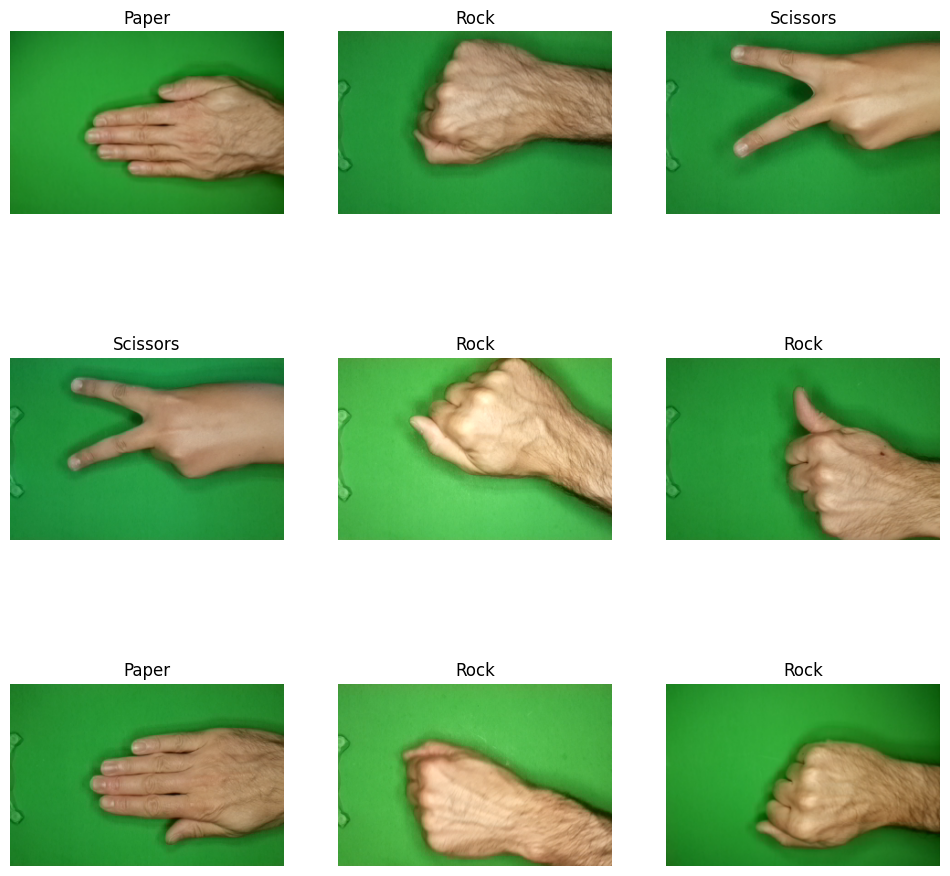

In [ ]:
#Visualizando ejemplos
plt.figure(figsize=(12, 12))
random_idx = np.random.choice(data_df.index, size=9, replace=False)

# Seleccionamos las 9 filas aleatorias del DataFrame
for i, row in enumerate(data_df.loc[random_idx].itertuples()):
    plt.subplot(3, 3, i + 1)
    # Cargamos la imagen desde la ruta
    imagen = plt.imread(row.filepath)
    plt.imshow(imagen)
    plt.title(row.label.capitalize())
    plt.axis("off")

plt.show()

## Preprocesamiento: redimensionado y normalización

Todas las imágenes se redimensionan a una resolución uniforme y se normalizan dividiendo entre 255 para llevar los píxeles a la escala [0, 1]. Las imágenes originales miden 200×300 px; se usa 128×128 para reducir memoria y tiempo de entrenamiento.


In [ ]:
IMG_SIZE = (100, 150)

def procesar_imagen(ruta):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return (img / 255.0).numpy()

imagenes_procesadas = [procesar_imagen(ruta) for ruta in data_df['filepath']]

### Visualización de imágenes normalizadas

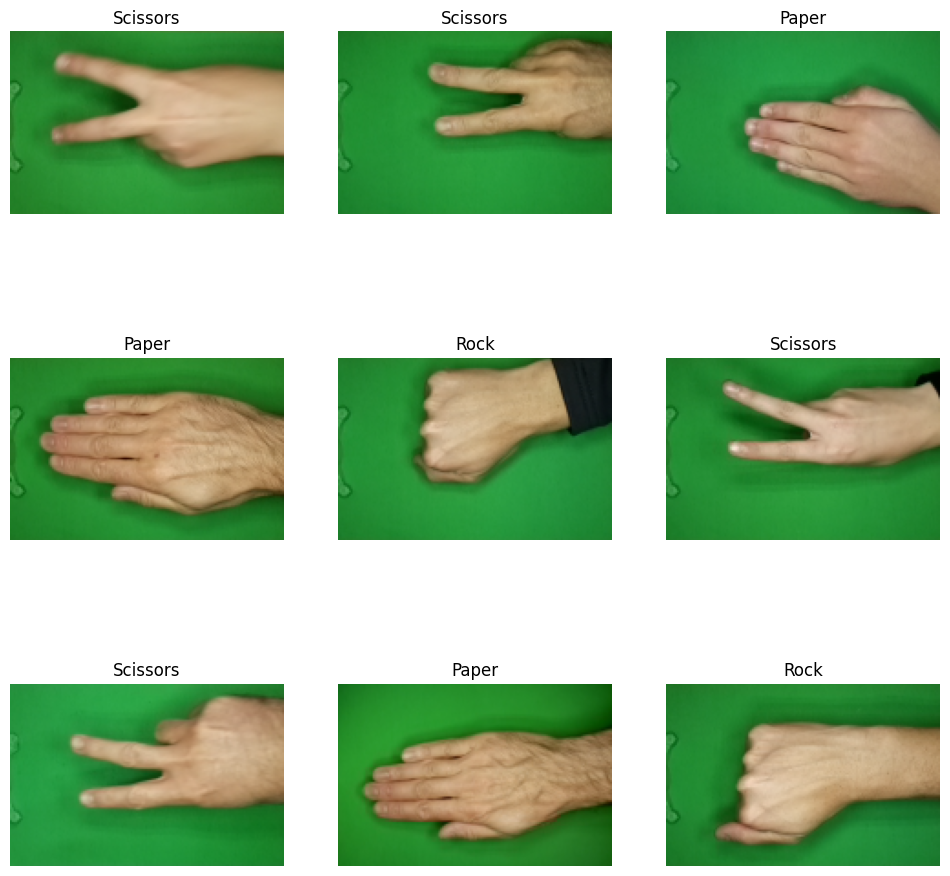

In [ ]:
plt.figure(figsize=(12, 12))
# Visualizamos 9 imágenes aleatorias de la lista de imágenes normalizadas
random_idx = np.random.choice(len(imagenes_procesadas), size=9, replace=False)

for i, idx in enumerate(random_idx):
    plt.subplot(3, 3, i + 1)
    # imagenes_procesadas ya contiene tensores normalizados (valores entre 0 y 1)
    imagen = imagenes_procesadas[idx]
    plt.imshow(imagen)
    plt.title(data_df.iloc[idx]['label'].capitalize())
    plt.axis("off")

plt.show()

## División de los datos (Train, Validation y Test)

División estratificada 70 % entrenamiento, 15 % validación y 15 % prueba. La validación se usa para monitorear el entrenamiento y el test solo para la evaluación final.

In [ ]:
# 1. Convertimos la lista de imágenes a un arreglo de NumPy (X)
X = np.array(imagenes_procesadas)

# 2. Convertimos las etiquetas de texto a números (Y)
# Por ejemplo: paper=0, rock=1, scissors=2
labels_numeric, unique_labels = pd.factorize(data_df["label"])
Y = np.array(labels_numeric)
class_names = unique_labels.tolist()

# 3. Dividimos los datos (70% entrenamiento, 15% validación, 15% prueba)
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.30, random_state=42, stratify=Y)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.50, random_state=42, stratify=Y_temp)

print("Tamaño del set de entrenamiento:", X_train.shape)
print("Tamaño del set de validación:", X_val.shape)
print("Tamaño del set de prueba:", X_test.shape)
print("Etiquetas únicas:", class_names)

Tamaño del set de entrenamiento: (1531, 100, 150, 3)
Tamaño del set de validación: (328, 100, 150, 3)
Tamaño del set de prueba: (329, 100, 150, 3)
Etiquetas únicas: ['paper', 'rock', 'scissors']


In [ ]:
NUM_CLASES = len(class_names)

Y_train_oh = to_categorical(Y_train, NUM_CLASES)
Y_val_oh = to_categorical(Y_val, NUM_CLASES)
Y_test_oh = to_categorical(Y_test, NUM_CLASES)

# Arquitectura de la Red Neuronal

Tres bloques `Conv2D` + `MaxPooling2D` (32, 64 y 128 filtros de 3×3 con ReLU; cada pooling de 2×2 reduce a la mitad el tamaño espacial), seguidos de `Flatten`, una capa `Dense` intermedia de 128 neuronas y una capa de salida con 3 neuronas y `softmax`. Se agrega `Dropout(0.5)` antes de la capa densa para reducir el sobreajuste, ya que el dataset es pequeño (2188 imágenes).

In [ ]:
model = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 148, 32)    │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 21760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 21760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,785,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,879,043 (10.98 MB)

 Trainable params: 2,879,043 (10.98 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# Entrenamiento

In [ ]:
BATCH_SIZE = 32
EPOCHS = 15

history = model.fit(
    X_train, Y_train_oh,
    validation_data=(X_val, Y_val_oh),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
)

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 26s 290ms/step - accuracy: 0.7773 - loss: 0.5518 - val_accuracy: 0.9268 - val_loss: 0.2370
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9445 - loss: 0.1575 - val_accuracy: 0.9543 - val_loss: 0.1381
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9732 - loss: 0.0792 - val_accuracy: 0.9329 - val_loss: 0.1775
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9719 - loss: 0.0777 - val_accuracy: 0.9634 - val_loss: 0.1179
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9713 - loss: 0.0918 - val_accuracy: 0.9726 - val_loss: 0.0875
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9856 - loss: 0.0448 - val_accuracy: 0.9604 - val_loss: 0.1499
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9843 - loss: 0.0373 - val_accuracy: 0.9756 - val_loss: 0.0952
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9941 - loss: 0.0188 - val_accuracy: 0.9665 - val_lo

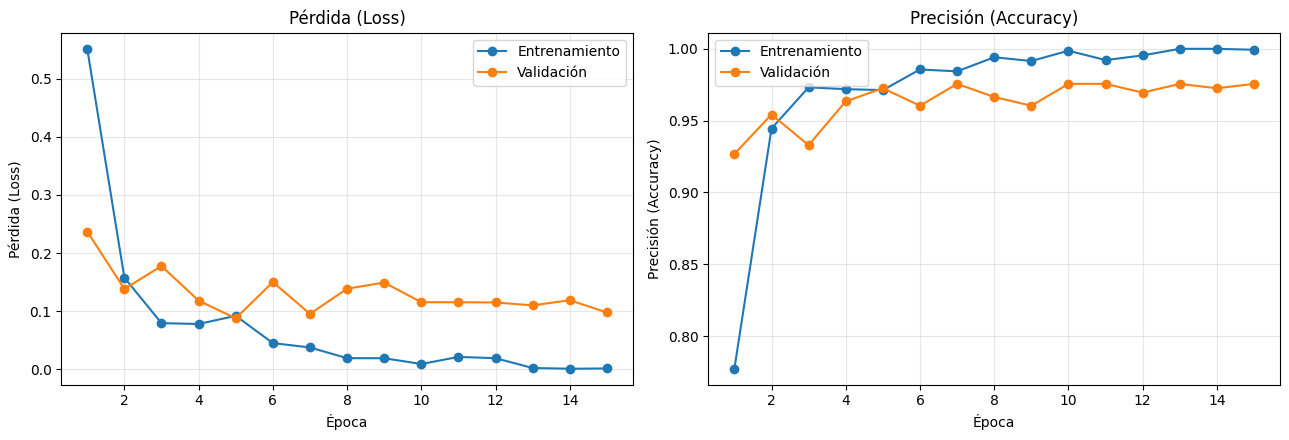

In [ ]:
epocas = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metrica, titulo in zip(axes, ["loss", "accuracy"], ["Pérdida (Loss)", "Precisión (Accuracy)"]):
    ax.plot(epocas, history.history[metrica], marker="o", label="Entrenamiento")
    ax.plot(epocas, history.history[f"val_{metrica}"], marker="o", label="Validación")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel(titulo)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Evaluación con el conjunto de prueba

In [ ]:
test_loss, test_acc = model.evaluate(X_test, Y_test_oh, verbose=0)
print(f"Pérdida en test: {test_loss:.4f}")
print(f"Precisión en test: {test_acc:.4f}")

Pérdida en test: 0.0631
Precisión en test: 0.9878


# Análisis

### Matriz de Confusión

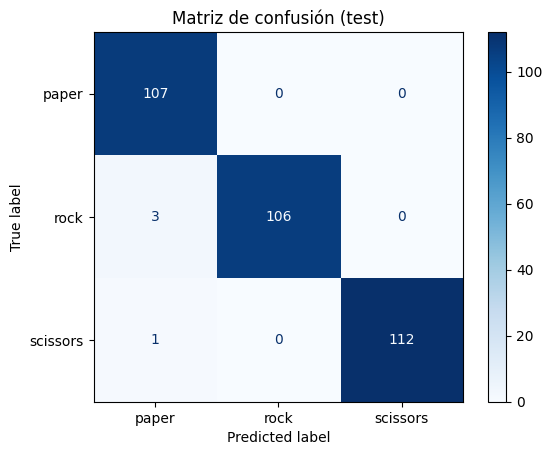

In [ ]:
probs = model.predict(X_test, verbose=0)
Y_pred = np.argmax(probs, axis=1)

cm = confusion_matrix(Y_test, Y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Matriz de confusión (test)")
plt.show()

### Reporte de clasificación (precision, recall y F1 por clase)

In [ ]:
print(classification_report(Y_test, Y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

       paper      0.964     1.000     0.982       107
        rock      1.000     0.972     0.986       109
    scissors      1.000     0.991     0.996       113

    accuracy                          0.988       329
   macro avg      0.988     0.988     0.988       329
weighted avg      0.988     0.988     0.988       329



### Confusiones ordenadas de mayor a menor

In [ ]:
errores = cm.copy()
np.fill_diagonal(errores, 0)

pares = [(class_names[i], class_names[j], errores[i, j]) for i in range(NUM_CLASES) for j in range(NUM_CLASES) if i != j]
print(f"Errores totales: {errores.sum()} de {len(Y_test)} imágenes de test\n")
for real, pred, n in sorted(pares, key=lambda p: -p[2]):
    print(f"Real '{real}' predicho como '{pred}': {n}")

Errores totales: 4 de 329 imágenes de test

Real 'rock' predicho como 'paper': 3
Real 'scissors' predicho como 'paper': 1
Real 'paper' predicho como 'rock': 0
Real 'paper' predicho como 'scissors': 0
Real 'rock' predicho como 'scissors': 0
Real 'scissors' predicho como 'rock': 0


### Ejemplos acertados y fallados

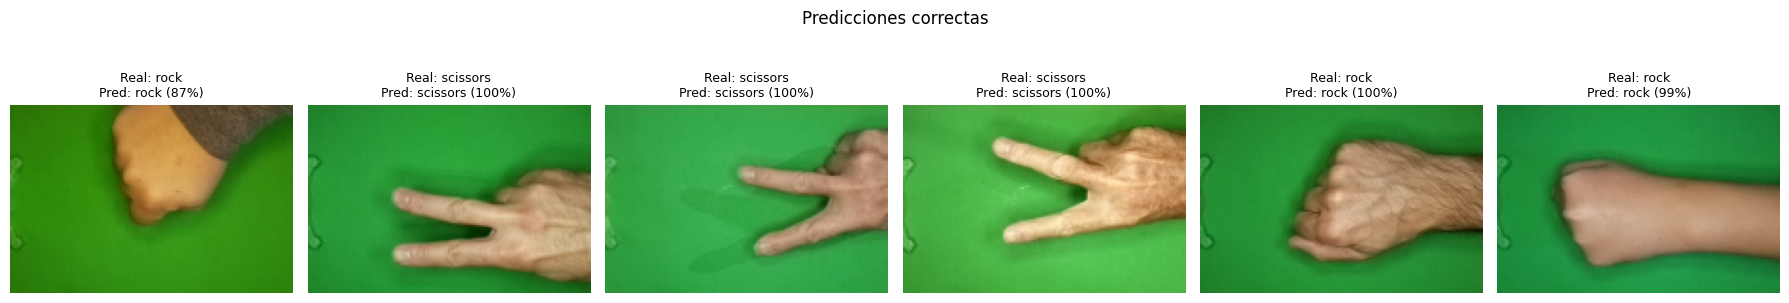

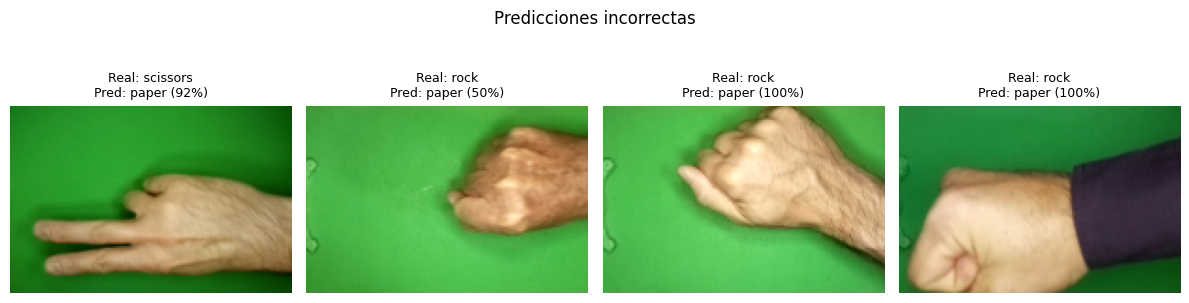

In [ ]:
aciertos = np.where(Y_pred == Y_test)[0]
fallos = np.where(Y_pred != Y_test)[0]
rng = np.random.default_rng(42)

def mostrar(indices, titulo, n=6):
    if len(indices) == 0:
        print(f"{titulo}: no hay ejemplos")
        return
    elegidos = rng.choice(indices, size=min(n, len(indices)), replace=False)
    plt.figure(figsize=(3 * len(elegidos), 3.6))
    for k, idx in enumerate(elegidos):
        plt.subplot(1, len(elegidos), k + 1)
        plt.imshow(X_test[idx])
        plt.title(f"Real: {class_names[Y_test[idx]]}\nPred: {class_names[Y_pred[idx]]} ({probs[idx].max():.0%})", fontsize=9)
        plt.axis("off")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar(aciertos, "Predicciones correctas")
mostrar(fallos, "Predicciones incorrectas")